# KINO io layer: what actually works today

**Scope note.** This notebook is *not* the end-to-end kinematic-lensing
showcase — that one is `04_one_galaxy_inference.ipynb`, which now runs end
to end against the real `kino.galaxy`/`kino.lensing`/`kino.instruments`/
`kino.inference` API (galaxy -> shear -> IFU -> moment maps ->
`IFUMomentLikelihood` -> `fit_shear`).

This notebook instead demonstrates `kino.io`: the `Datacube` container and
the KinMS-backed known-truth cube generator (`TEST_DATA.md` Tier A).
Every cell below actually executes.

We'll:
1. Generate a known-truth rotating-disc datacube with `kino.io.kinms`.
2. Visualize its flux map, velocity moment map, and central spectrum.
3. Demonstrate the two physical/convention invariants pinned down by
   `tests/io/test_kinms.py`: a face-on disc has no systematic velocity
   gradient, and the kinematic major axis tracks KINO's East-of-North
   position angle.
4. Show `Datacube`'s own input validation.

Requires the `data` and `notebooks` extras: `pip install -e ".[dev,data,notebooks]"`.


## 0. Setup

In [1]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

import kino
from kino.io.base import Datacube
from kino.io.kinms import generate_disc_cube

rng = np.random.default_rng(seed=0)  # explicit, seeded RNG -- see CLAUDE.md conventions
print("kino", kino.__version__)

kino 0.1.0.dev0


## 1. Generate a known-truth disc cube

A modest exponential-ish disc, moderately inclined, with a rising-then-flat
rotation curve -- the same shape of inputs `kino.galaxy.DiscGalaxy` will
eventually produce, but here specified by hand and fed straight to KinMS.

In [2]:
cube = generate_disc_cube(
    field_of_view=40 * u.arcsec,
    pixel_scale=1 * u.arcsec,
    velocity_range=600 * u.km / u.s,
    channel_width=15 * u.km / u.s,
    beam_size=2 * u.arcsec,
    inc=55,  # degrees; 0 = face-on, 90 = edge-on
    pa=30,  # degrees, East of North
    sb_rad=[0, 5, 10, 15] * u.arcsec,
    sb_prof=[1.0, 0.8, 0.3, 0.0],
    vel_rad=[0, 3, 8, 20] * u.arcsec,
    vel_prof=[0, 120, 180, 180] * u.km / u.s,
    gas_sigma=15 * u.km / u.s,
    v_sys=0 * u.km / u.s,
    n_clouds=300_000,
    rng=rng,
)
cube.shape, cube.spectral_kind, cube.pixel_scale, cube.flux_unit

((40, 40, 40), 'velocity', <Quantity 1. arcsec>, Unit(dimensionless))

## 2. Visualize: flux map, velocity map, central spectrum

`Datacube.flux` is `(n_spec, n_y, n_x)`. Collapsing over the spectral axis
gives the flux (moment 0) map; a flux-weighted mean of the spectral axis
gives the line-of-sight velocity (moment 1) map.

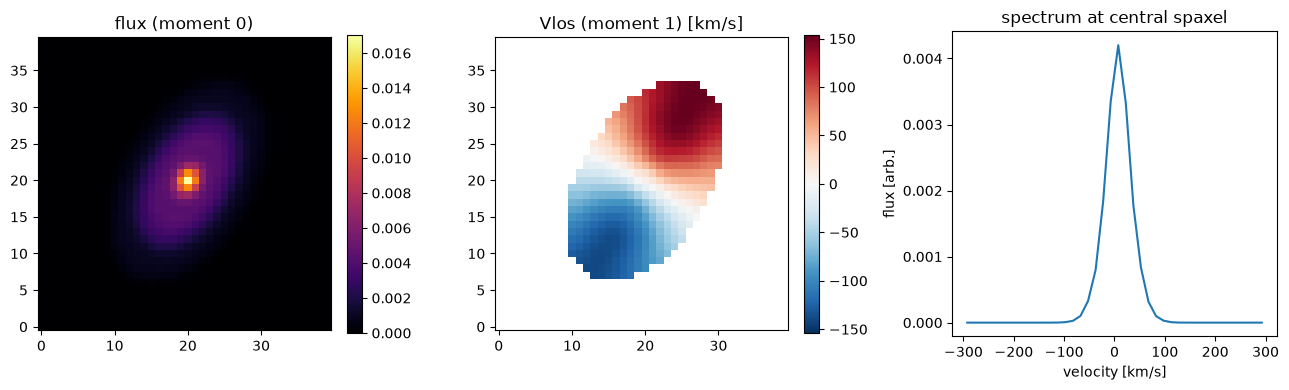

In [3]:
v = cube.spectral_axis.to_value(u.km / u.s)[:, None, None]
flux_map = cube.flux.sum(axis=0)
with np.errstate(invalid="ignore", divide="ignore"):
    vel_map = (cube.flux * v).sum(axis=0) / flux_map
vel_map = np.where(flux_map > 0.02 * flux_map.max(), vel_map, np.nan)

ny, nx = flux_map.shape
cy, cx = ny // 2, nx // 2

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

im0 = axes[0].imshow(flux_map, origin="lower", cmap="inferno")
axes[0].set_title("flux (moment 0)")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

vmax = np.nanmax(np.abs(vel_map))
im1 = axes[1].imshow(vel_map, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[1].set_title("Vlos (moment 1) [km/s]")
fig.colorbar(im1, ax=axes[1], fraction=0.046)

axes[2].plot(cube.spectral_axis.to_value(u.km / u.s), cube.flux[:, cy, cx])
axes[2].set_xlabel("velocity [km/s]")
axes[2].set_ylabel("flux [arb.]")
axes[2].set_title("spectrum at central spaxel")

fig.tight_layout()

## 3. Invariant: face-on disc has no systematic velocity gradient

At `inc=0`, `sin(inc)=0`, so a purely circular rotation curve contributes
nothing to the line-of-sight velocity anywhere in the disc -- the whole
moment-1 map should sit at `v_sys` (here, 0), independent of `pa`. This is
the same check as `tests/io/test_kinms.py::test_face_on_disc_has_no_systematic_velocity_gradient`.

max |Vlos| where there's signal: 7.50 km/s
channel width:                  15.00 km/s  (should dominate the above)


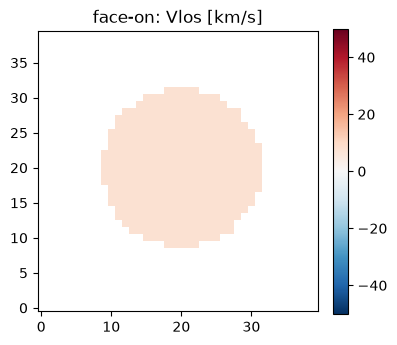

In [4]:
cube_faceon = generate_disc_cube(
    field_of_view=40 * u.arcsec,
    pixel_scale=1 * u.arcsec,
    velocity_range=600 * u.km / u.s,
    channel_width=15 * u.km / u.s,
    beam_size=2 * u.arcsec,
    inc=0,
    pa=30,
    sb_rad=[0, 5, 10, 15] * u.arcsec,
    sb_prof=[1.0, 0.8, 0.3, 0.0],
    vel_rad=[0, 3, 8, 20] * u.arcsec,
    vel_prof=[0, 120, 180, 180] * u.km / u.s,
    gas_sigma=0 * u.km / u.s,
    n_clouds=300_000,
    rng=rng,
)
v = cube_faceon.spectral_axis.to_value(u.km / u.s)[:, None, None]
flux_map_fo = cube_faceon.flux.sum(axis=0)
with np.errstate(invalid="ignore", divide="ignore"):
    vel_map_fo = (cube_faceon.flux * v).sum(axis=0) / flux_map_fo
signal = flux_map_fo > 0.05 * flux_map_fo.max()

print(f"max |Vlos| where there's signal: {np.nanmax(np.abs(vel_map_fo[signal])):.2f} km/s")
print(f"channel width:                  {15:.2f} km/s  (should dominate the above)")

plt.figure(figsize=(4, 4))
plt.imshow(np.where(signal, vel_map_fo, np.nan), origin="lower", cmap="RdBu_r", vmin=-50, vmax=50)
plt.title("face-on: Vlos [km/s]")
plt.colorbar(fraction=0.046);

## 4. Convention: position angle is East of North

KINO defines `pa` in degrees East of North (`x` = East, `y` = North). KinMS's
own `posAng` rotates the *opposite* sense, so `kino.io.kinms` negates it
internally (see the module docstring in `kino/io/kinms.py` for the full
derivation). The visible effect: the kinematic major axis should lie along
**y** (vertical, North) at `pa=0`, and along **x** (horizontal, East) at
`pa=90`.

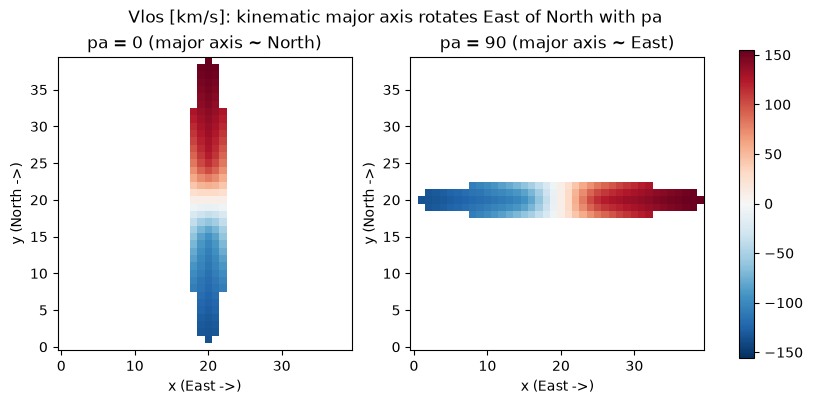

In [5]:
def moment1(inc, pa, seed):
    c = generate_disc_cube(
        field_of_view=40 * u.arcsec,
        pixel_scale=1 * u.arcsec,
        velocity_range=600 * u.km / u.s,
        channel_width=20 * u.km / u.s,
        beam_size=2 * u.arcsec,
        inc=inc,
        pa=pa,
        sb_rad=[0, 15, 20] * u.arcsec,
        sb_prof=[1.0, 1.0, 0.0],
        vel_rad=[0, 5, 20] * u.arcsec,
        vel_prof=[0, 150, 150] * u.km / u.s,
        gas_sigma=5 * u.km / u.s,
        n_clouds=300_000,
        rng=np.random.default_rng(seed),
    )
    v = c.spectral_axis.to_value(u.km / u.s)[:, None, None]
    flux_map = c.flux.sum(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        vel_map = (c.flux * v).sum(axis=0) / flux_map
    signal = flux_map > 0.05 * flux_map.max()
    return np.where(signal, vel_map, np.nan)


vel_pa0 = moment1(inc=85, pa=0, seed=2)
vel_pa90 = moment1(inc=85, pa=90, seed=2)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
vmax = np.nanmax(np.abs(vel_pa0))
titles = ["pa = 0 (major axis ~ North)", "pa = 90 (major axis ~ East)"]
for ax, vel_map, title in zip(axes, [vel_pa0, vel_pa90], titles, strict=True):
    im = ax.imshow(vel_map, origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("x (East ->)")
    ax.set_ylabel("y (North ->)")
fig.colorbar(im, ax=axes, fraction=0.023)
fig.suptitle("Vlos [km/s]: kinematic major axis rotates East of North with pa");

> Only the axis **line** is pinned here (and by the corresponding unit
> test) -- which *end* of that line is redshifted is a separate
> sub-convention tied to the rotation-curve sign, not yet fixed anywhere in
> KINO since `kino.galaxy` doesn't exist. Don't read red/blue-side meaning
> into this plot yet.

## 5. `Datacube` validates its inputs

The container isn't just a bag of arrays -- shape/unit mismatches are
rejected at construction time (`tests/io/test_base.py`).

In [6]:
try:
    Datacube(
        flux=np.zeros((4, 3, 2)),
        spectral_axis=np.linspace(-100, 100, 5) * u.km / u.s,  # wrong length: 5 vs 4
        spectral_kind="velocity",
        pixel_scale=0.5 * u.arcsec,
        redshift=0.1,
        flux_unit=u.Jy,
    )
except ValueError as exc:
    print(f"rejected as expected: {exc}")

rejected as expected: spectral_axis shape (5,) does not match flux's spectral axis length 4


## What's next

- `kino.galaxy` (Phase 1): an intrinsic `DiscGalaxy` model, so cubes like
  the ones above come from physical parameters (r_e, inclination, v_flat,
  ...) instead of hand-picked profiles.
- `kino.lensing` (Phase 2): apply a shear to a scene before it reaches the
  instrument -- this notebook has no shear in it at all yet.
- `kino.instruments` (Phase 3) and `kino.inference` (Phase 5): turn a scene
  into a realistic mock observation and recover the shear back out with
  `nautilus`.

Once those land, `01_one_galaxy_inference.ipynb` becomes the real
end-to-end story; this notebook stays as the `kino.io` reference/demo.